In [ ]:
'''Q1. Fest Attendance Check

The organizers of a Tech Tatva want to know which events turn registrations into actual attendance.

events = {'event': ['City Scaping', 'salutes and ladders', 'Open Mic', '', 'Valorant tournament'],
         'registered': [180, 95, 140, 60, 210],
         'attended': [150, 70, 135, 52, 160],
         'fee': [200, 150, 0, 50, 100]}

Build a DataFrame and print its shape and dtypes. Add an attendance_rate column (attended ÷ registered × 100, rounded to 1 decimal).
Find the event with the most registrations and the event with the highest attendance rate. Interpret: are they the same event, and 
what does that say about judging an event by registrations alone?'''
import pandas as pd

events = {'event': ['City Scaping', 'salutes and ladders', 'Open Mic', '', 'Valorant tournament'],
         'registered': [180, 95, 140, 60, 210],
         'attended': [150, 70, 135, 52, 160],
         'fee': [200, 150, 0, 50, 100]}
df=pd.DataFrame(events)
print(df)
print("\n")
print(df.shape)
print(df.dtypes)
df['attendance_rate'] = (
    df['attended'] / df['registered'] * 100
).round(1)
print("\n")
print(df)
print("\n")
reg_event = df.loc[df['registered'].idxmax(), ['event', 'registered', 'attendance_rate']]
print("Most registered: \n", reg_event)
print("\n")
att_event=df.loc[df['attendance_rate'].idxmax(), ['event','registered', 'attendance_rate']]
print("Most attended: \n", att_event)

In [ ]:
'''Q2. Fitness Tracker Week

A fitness tracker exports one week of data as a NumPy array with columns steps, sleep_hours, active_minutes.

data = np.array([[8200, 7.5, 40], [10400, 6.5, 55], [6100, 8.0, 20], [12000, 6.0, 70],
                [9800, 7.0, 50], [3000, 9.0, 10], [7500, 8.5, 35]])
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

Build a DataFrame from the array using days as the index and proper column names. 
The array stores everything as float, so convert steps and active_minutes to integers. 
Use describe() to read the average steps and sleep, then use idxmax / idxmin to find the day with the most steps and 
the day with the least sleep. Interpret: seven days are too few to claim that busy days cause short sleep. 
What extra data would you want?'''
import pandas as pd
import numpy as np

data = np.array([[8200, 7.5, 40], [10400, 6.5, 55], [6100, 8.0, 20], [12000, 6.0, 70],
                [9800, 7.0, 50], [3000, 9.0, 10], [7500, 8.5, 35]])
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

df=pd.DataFrame(data,index=days, columns=['Steps', 'Sleep_hours', 'Active_Minutes'])
print(df)
print("\n")
df=df.astype({'Steps':'int64','Active_Minutes':'int64'})
print(df.describe().loc['mean',['Steps','Sleep_hours']].astype('int64'))
steps_max = df['Steps'].idxmax()
sleep_min=df['Sleep_hours'].idxmin()
print("\n")
print("Day with most steps: ", steps_max)
print("Day with min steps: ", sleep_min)

In [ ]:
'''songs = {'song': ['Neon Drive', 'Monsoon Loop', 'Gravity', 'Night Bus', 'Cherry Static', 'Dust Roads', 'Run It Back', 'Paper Moon'],
        'genre': ['Pop', 'LoFi', 'Rock', 'LoFi', 'Pop', 'Folk', 'HipHop', 'Folk'],
        'streams_k': [520, 310, 450, 280, 610, 150, 390, 205],
        'skip_pct': [18, 9, 32, 12, 41, 7, 27, 10],
        'duration_sec': [201, 245, 289, 198, 176, 310, 187, 262]}

Create the DataFrame and report its shape, dtypes and the number of distinct genres. List the top 3 songs by streams. Then find songs 
that are popular (more than 400k streams) and frequently skipped (skip rate above 25%). 
Interpret: what risk does the platform take if it recommends songs using stream counts only?'''
import pandas as pd
songs = {'song': ['Neon Drive', 'Monsoon Loop', 'Gravity', 'Night Bus', 'Cherry Static', 'Dust Roads', 'Run It Back', 'Paper Moon'],
        'genre': ['Pop', 'LoFi', 'Rock', 'LoFi', 'Pop', 'Folk', 'HipHop', 'Folk'],
        'streams_k': [520, 310, 450, 280, 610, 150, 390, 205],
        'skip_pct': [18, 9, 32, 12, 41, 7, 27, 10],
        'duration_sec': [201, 245, 289, 198, 176, 310, 187, 262]}
df=pd.DataFrame(songs)
print("Shape: ",df.shape)
print("dtype: \n",df.dtypes)
print("Number of unique genres: ", len(df['genre'].unique()))
print("\n")
top_3 = df.sort_values(by='streams_k', ascending=False).head(3)
print(top_3)
print("\n")
print("Frequently skipped popular songs: \n", df[(df['streams_k'] > 400) & (df['skip_pct'] > 25)])

In [ ]:
'''Q4. Mess Rush Hour

canteen = {'hour': [8, 9, 10, 11, 12, 13, 14, 15, 16, 17],
          'sold': [40, 55, 35, 90, 210, 180, 60, 30, 70, 95],
          'prepared': [50, 60, 50, 100, 220, 230, 80, 60, 90, 110]}

Build the DataFrame and set hour as the index. Using loc, select sold for hours 11 to 13. Using iloc, select the rows at positions 3 and 4. 
Use a Boolean mask to find the busy hours (at least 90 items sold). 
Interpret: loc[11:13] and iloc[3:5] both look like slices ending at 13 and 5. Why do they return different numbers of rows?'''
import pandas as pd
canteen = {'hour': [8, 9, 10, 11, 12, 13, 14, 15, 16, 17],
          'sold': [40, 55, 35, 90, 210, 180, 60, 30, 70, 95],
          'prepared': [50, 60, 50, 100, 220, 230, 80, 60, 90, 110]}
df=pd.DataFrame(canteen, index=canteen['hour'])
print(df.loc[11:13, 'sold'])
print("\n")
print(df.iloc[3:5,1])
print("\n")
print(df[df['sold'] >= 90])

In [ ]:
'''Q5. Is the Busiest Hour the Most Wasteful?

Using the Q4 data, add waste (prepared − sold) and waste_pct (waste ÷ prepared × 100). Identify (a) the hour with the most items sold, 
(b) the hour with the highest absolute waste, and (c) the hour with the highest waste percentage. 
Decision: the canteen can cut preparation in only one hour. Which hour would you choose and why?'''
import pandas as pd
canteen = {'hour': [8, 9, 10, 11, 12, 13, 14, 15, 16, 17],
          'sold': [40, 55, 35, 90, 210, 180, 60, 30, 70, 95],
          'prepared': [50, 60, 50, 100, 220, 230, 80, 60, 90, 110]}
df=pd.DataFrame(canteen, index=canteen['hour'])
df['waste']= (df['prepared']-df['sold'])
df['waste_pct']=(df['waste']/df['prepared']*100)
most_sold=df['sold'].idxmax()
most_waste=df['waste'].idxmax()
most_waste_per=df['waste_pct'].idxmax()
print("The hour with the most sold:", most_sold, "with", df.loc[most_sold, 'sold'], "sold")
print("\n")
print("The hour with the highest absolute waste:", most_waste, "with waste as", df.loc[most_waste, 'waste'])
print("\n")
print("The hour with the highest waste percentage:", most_waste_per, "with waste percentage as", df.loc[most_waste_per, 'waste_pct'])

In [ ]:
'''Q6. Online Store Catalog Search

catalog = {'product': ['USB-C Hub Pro', 'Notebook A5', 'Gel Pen Pack', 'Laptop Stand Pro',
                      'Desk Lamp', 'Mouse Pad XL', 'Webcam Pro', 'Sticky Notes'],
          'category': ['Electronics', 'Stationery', 'Stationery', 'Electronics',
                       'Home', 'Accessories', 'Electronics', 'Stationery'],
          'price': [1299, 120, 90, 1599, 899, 349, 2499, 60],
          'units_sold': [85, 400, 520, 60, 110, 230, 25, 610]}

The store manager asks four questions. Answer each with one filter: (a) products whose name contains Pro; 
(b) products in the Stationery or Home categories (isin); (c) products priced between 300 and 1500 inclusive (between); 
(d) Pro products that sold fewer than 70 units. Interpret: what does (d) suggest about premium products in this store?'''
import pandas as pd
catalog = {'product': ['USB-C Hub Pro', 'Notebook A5', 'Gel Pen Pack', 'Laptop Stand Pro',
                      'Desk Lamp', 'Mouse Pad XL', 'Webcam Pro', 'Sticky Notes'],
          'category': ['Electronics', 'Stationery', 'Stationery', 'Electronics',
                       'Home', 'Accessories', 'Electronics', 'Stationery'],
          'price': [1299, 120, 90, 1599, 899, 349, 2499, 60],
          'units_sold': [85, 400, 520, 60, 110, 230, 25, 610]}
df=pd.DataFrame(catalog, index=catalog['product'])
print(df[df['product'].str.contains('Pro')])
print("\n")
print(df[df['category'].isin(['Stationery', 'Home'])])
print("\n")
print(df[df['price'].between(300,1500)])
print("\n")
print(df[(df['product'].str.contains('Pro'))&(df['units_sold']<70)])


In [ ]:
'''Q7. The Faulty Manipal Weather Station

weather = pd.DataFrame({'day': range(1, 11),
                       'temp_c': [28.1, 29.0, np.nan, 30.2, 29.5, 55.0, np.nan, 27.8, 28.6, 29.3],
                       'humidity': [64, 61, 63, np.nan, 60, 58, np.nan, 66, 65, 62]})

Count missing values per column and the number of rows with at least one missing value. Drop rows where both readings are missing. 
Then fill the remaining missing temp_c and humidity values with the median of each column. Day 6 (55.0 °C) is almost certainly 
a sensor fault. Interpret: compare the temperature mean and median. Why is the median the safer fill value here?'''
import pandas as pd
import numpy as np
weather = pd.DataFrame({'day': range(1, 11),
                       'temp_c': [28.1, 29.0, np.nan, 30.2, 29.5, 55.0, np.nan, 27.8, 28.6, 29.3],
                       'humidity': [64, 61, 63, np.nan, 60, 58, np.nan, 66, 65, 62]})
df=pd.DataFrame(weather)
print("Missing values per column:")
print(weather.isna().sum())
print("\nRows with at least one missing value:")
print(weather.isna().any(axis=1).sum())
df = df.dropna(subset=['temp_c', 'humidity'], how='all')
df['temp_c']=df['temp_c'].fillna(weather['temp_c'].median())
print("\n")
print(df)


In [ ]:
'''Q8. Ohms Xerox Duplicate Orders and Messy Product Names

orders = pd.DataFrame({
   'order_id': [101, 102, 103, 101, 104, 105, 106, 105],
   'customer': ['Asha', 'ravi', 'Meera', 'Asha', 'Kiran', 'ravi', 'Meera', 'Ravi'],
   'product': ['laptop bag', 'Laptop Bag ', 'desk lamp', 'laptop bag', 'DESK LAMP', 'notebook', 'Notebook', 'Notebook '],
   'amount': [1200, 1200, 900, 1200, 900, 150, 150, 150]})

First call drop_duplicates() on the raw data and note the row count. Then clean the text (strip spaces, consistent capitalization) in 
customer and product, and remove duplicates again. Compute total revenue before cleaning and after cleaning. 
Interpret: by what percentage did bad data inflate the revenue figure, and why did the first attempt miss a duplicate?'''

import pandas as pd

orders = pd.DataFrame({
   'order_id': [101, 102, 103, 101, 104, 105, 106, 105],
   'customer': ['Asha', 'ravi', 'Meera', 'Asha', 'Kiran', 'ravi', 'Meera', 'Ravi'],
   'product': ['laptop bag', 'Laptop Bag ', 'desk lamp', 'laptop bag', 'DESK LAMP', 'notebook', 'Notebook', 'Notebook '],
   'amount': [1200, 1200, 900, 1200, 900, 150, 150, 150]})
print("Original data count:", len(orders))
rev_bfr=orders['amount'].sum()
orders1=orders.drop_duplicates().copy()
print("The new row count:", len(orders1))

print("Revenue before:", rev_bfr)
orders1['customer'] = orders1['customer'].str.strip().str.title()
orders1['product'] = orders1['product'].str.strip().str.title()
clean_orders = orders1.drop_duplicates()
rev_aft=clean_orders['amount'].sum()
print("Revenue after:", rev_aft)

In [ ]:
'''Q9.
players = pd.DataFrame({'player': ['A', 'B', 'C', 'D', 'E', 'F'],
                       'score': [4200, 1800, 7600, 3100, 5900, 900],
                       'minutes': [30, 45, 60, 20, 40, 15]})

Using a vectorized operation, add score_per_min. Using apply with a small function, add a tier column: Elite for scores of 6000 or more, 
Skilled for 3000 to 5999, Rookie otherwise. Using map, convert the tier into bonus points (Elite 500, Skilled 200, Rookie 50) and 
compute the total bonus. Interpret: is the top scorer also the most efficient player?'''
import pandas as pd

def assign_tier(score):
    if score >= 6000:
        return 'Elite'
    elif score >= 3000:
        return 'Skilled'
    else:
        return 'Rookie'

players = pd.DataFrame({'player': ['A', 'B', 'C', 'D', 'E', 'F'],
                       'score': [4200, 1800, 7600, 3100, 5900, 900],
                       'minutes': [30, 45, 60, 20, 40, 15]})
players['score_per_min']=players['score']/players['minutes']
players['tier'] = players['score'].apply(assign_tier)
bonus_map = {
'Elite': 500,
'Skilled': 200,
'Rookie': 50
}
players['bonus'] = players['tier'].map(bonus_map)

total_bonus = players['bonus'].sum()

print(players)
print("\n")
print("Total bonus points:", total_bonus)

In [ ]:
'''Q10. Do MidSem Averages Hide Inconsistency?

marks = pd.DataFrame({
   'subject': ['Maths']*4 + ['Physics']*4 + ['Pps']*4,
   'marks': [72, 74, 70, 73, 60, 95, 50, 85, 80, 78, 82, 84]})

Group by subject and compute the mean, standard deviation, minimum and maximum marks in one agg call. Rank the subjects by mean, then 
by standard deviation. Interpret: two subjects have almost the same average. Which one would a teacher need to investigate further and why?'''
import pandas as pd
marks = pd.DataFrame({
   'subject': ['Maths']*4 + ['Physics']*4 + ['Pps']*4,
   'marks': [72, 74, 70, 73, 60, 95, 50, 85, 80, 78, 82, 84]})
#print(marks)
summary = marks.groupby('subject')['marks'].agg(
['mean', 'std', 'min', 'max']
)

print("Subject-wise statistics:")
print(summary)
print("\nRanked by mean marks:")
print(summary.sort_values(by='mean', ascending=False))
print("\nRanked by standard deviation:")
print(summary.sort_values(by='std', ascending=False))


In [ ]:
'''An online store investigates which product to promote.

sales = pd.DataFrame({
   'product': ['Phone Case', 'Phone Case', 'Earbuds', 'Earbuds', 'Smart Watch', 'Smart Watch',
               'Power Bank', 'Power Bank', 'Screen Guard', 'Screen Guard'],
   'month': ['Aug', 'Sep'] * 5,
   'units': [180, 120, 100, 50, 50, 40, 90, 110, 300, 200],
   'price': [299, 299, 1499, 1499, 2999, 2999, 999, 999, 99, 99],
   'cost': [120, 120, 1300, 1300, 2700, 2700, 650, 650, 40, 40]})

Create revenue and profit columns per row, then group by product and sum both. Sort to find the leader for each measure and 
compute each product’s profit margin (total profit ÷ total revenue × 100). Decision: which product deserves the promotion budget, 
and which one looks successful only because of its price?'''

import pandas as pd
sales = pd.DataFrame({
   'product': ['Phone Case', 'Phone Case', 'Earbuds', 'Earbuds', 'Smart Watch', 'Smart Watch',
               'Power Bank', 'Power Bank', 'Screen Guard', 'Screen Guard'],
   'month': ['Aug', 'Sep'] * 5,
   'units': [180, 120, 100, 50, 50, 40, 90, 110, 300, 200],
   'price': [299, 299, 1499, 1499, 2999, 2999, 999, 999, 99, 99],
   'cost': [120, 120, 1300, 1300, 2700, 2700, 650, 650, 40, 40]})

sales['profit']=(sales['price']-sales['cost'])*sales['units']
sales['revenue']=sales['price']*sales['units']
group=sales.groupby('product')[['revenue', 'profit']].sum()
print(group)
group['profit_margin'] = group['profit'] / group['revenue'] * 100
print("\nRanked by revenue:")
print(group.sort_values(by='revenue', ascending=False))
print("\nRanked by profit:")
print(group.sort_values(by='profit', ascending=False))
print("\nProfit margins:")
print(group['profit_margin'].sort_values(ascending=False))


In [ ]:
'''Q12. The Misleading Conversion Rate-Ambani wants to compete with elon musks starlink

jio compares two marketing channels. A teammate wrote the code below and concluded that Channel A wins.

funnel = pd.DataFrame({'channel': ['A', 'A', 'B', 'B'],
                      'visitors': [10, 490, 100, 100],
                      'signups': [6, 49, 20, 20]})
funnel['rate'] = funnel['signups'] / funnel['visitors'] * 100
print(funnel.groupby('channel')['rate'].mean())

Run the code and note the result. Explain what is wrong with averaging the daily rates when the visitor counts differ so much. Fix 
the analysis by aggregating the right columns first and computing the rate afterwards. Decision: which channel should the jio invest in?'''

import pandas as pd

funnel = pd.DataFrame({'channel': ['A', 'A', 'B', 'B'],
                      'visitors': [10, 490, 100, 100],
                      'signups': [6, 49, 20, 20]})

funnel['rate'] = funnel['signups'] / funnel['visitors'] * 100
print(funnel.groupby('channel')['rate'].mean())

summary = funnel.groupby('channel')[['visitors', 'signups']].sum()
print("\n")
print(summary)
summary['rate'] = summary['signups'] / summary['visitors'] * 100
print("\n")
print(summary)

In [ ]:
'''Q13. The Catalog Gap

tracks = pd.DataFrame({'track_id': [1, 2, 3, 4],
                      'title': ['Neon Drive', 'Gravity', 'Night Bus', 'Dust Roads'],
                      'artist': ['Aria', 'Vega', 'Aria', 'Mohan']})
plays = pd.DataFrame({'track_id': [1, 2, 3, 5], 'plays': [520, 450, 280, 90]})

Merge the tables with an inner, a left and an outer join, and record the row count of each. The platform wants a report listing every 
catalog track, including tracks never played. Choose the correct join, fill missing plays with 0, and compute total plays per artist. 
Interpret: what does the unmatched track_id 5 tell you about the data, and which join type hides it?'''

import pandas as pd

tracks = pd.DataFrame({'track_id': [1, 2, 3, 4],
                      'title': ['Neon Drive', 'Gravity', 'Night Bus', 'Dust Roads'],
                      'artist': ['Aria', 'Vega', 'Aria', 'Mohan']})
plays = pd.DataFrame({'track_id': [1, 2, 3, 5], 'plays': [520, 450, 280, 90]})

inner = pd.merge(tracks, plays, on='track_id', how='inner')
print("Inner join row count:", len(inner))
print(inner)
print("\n")

left = pd.merge(tracks, plays, on='track_id', how='left')
print("Left join row count:", len(left))
print(left)
print("\n")

outer = pd.merge(tracks, plays, on='track_id', how='outer')
print("Outer join row count:", len(outer))
print(outer)
print("\n")

report = pd.merge(tracks, plays, on='track_id', how='left')

report['plays'] = report['plays'].fillna(0)

print("\nCatalog report:")
print(report)

artist_plays = report.groupby('artist')['plays'].sum()

print("\nTotal plays per artist:")
print(artist_plays)



In [ ]:
'''Q14. Delhi’s Traffic and Air Quality

Two weekly logs from a city monitoring station have the same columns.

week1 = pd.DataFrame({'vehicles_k': [30, 35, 40, 45], 'pm25': [52, 55, 60, 63]})
week2 = pd.DataFrame({'vehicles_k': [50, 55, 60, 65], 'pm25': [68, 72, 75, 80]})

Combine them with concat (reset the index) and add a week column. Compute the correlation between vehicles and PM2.5 and 
the mean PM2.5 for each week. Interpret: if the city declares an alert when the weekly mean exceeds 70, which week triggers it? 
Name one other factor besides traffic that could also influence PM2.5.'''

import pandas as pd
week1 = pd.DataFrame({'vehicles_k': [30, 35, 40, 45], 'pm25': [52, 55, 60, 63]})
week1['week']='Week 1'
week2 = pd.DataFrame({'vehicles_k': [50, 55, 60, 65], 'pm25': [68, 72, 75, 80]})
week2['week']='Week 2'
df=pd.concat([week1, week2], ignore_index=True)

correlation = df['vehicles_k'].corr(df['pm25'])
print("\nCorrelation:", correlation)

print(df.groupby('week')['pm25'].mean())



In [ ]:
'''The fest committee wants revenue by department, but the registration sheet is messy.

regs = pd.DataFrame({
   'reg_id': range(1, 12),
   'student': ['Anu', 'Bala', 'Chitra', 'Anu', 'Dev', 'Esha', 'Farhan', 'Gita', 'Bala', 'Hari', 'Ira'],
   'event': [' city landscaping ', 'city landscaping ', 'salutes and ladders', ' city landscaping ', 'Open Mic', 'open mic',
             'ROBO RACE', 'Quiz Night', 'hackathon', 'Quiz Night', 'Hackathon'],
   'dept': ['CSE', 'cse', 'ECE', 'CSE', 'MECH', 'CSE', 'ECE', None, 'CSE', 'ECE', 'ECE']})
fees = pd.DataFrame({'event': ['Hackathon', 'Robo Race', 'Open Mic', 'Quiz Night'],
                    'fee': [200, 150, 0, 50]})

Clean event and dept text, treat a repeated (student, event) pair as one registration, fill the missing department with Unknown, 
merge with fees, and compute registrations per event and revenue per department. Then repeat the department revenue calculation without 
removing duplicates. Interpret: how would the duplicates have changed the committee’s conclusion?'''

import pandas as pd
regs = pd.DataFrame({
   'reg_id': range(1, 12),
   'student': ['Anu', 'Bala', 'Chitra', 'Anu', 'Dev', 'Esha', 'Farhan', 'Gita', 'Bala', 'Hari', 'Ira'],
   'event': [' city landscaping ', 'city landscaping ', 'salutes and ladders', ' city landscaping ', 'Open Mic', 'open mic',
             'ROBO RACE', 'Quiz Night', 'hackathon', 'Quiz Night', 'Hackathon'],
   'dept': ['CSE', 'cse', 'ECE', 'CSE', 'MECH', 'CSE', 'ECE', None, 'CSE', 'ECE', 'ECE']})
fees = pd.DataFrame({'event': ['Hackathon', 'Robo Race', 'Open Mic', 'Quiz Night'],
                    'fee': [200, 150, 0, 50]})
#print(regs)
#print("\n")

regs['event']=regs['event'].str.title().str.strip()
regs['dept']=regs['dept'].str.title().str.strip().fillna('Unknown')

df_og=pd.merge(regs, fees, on='event', how='left')
print("Registerations per event: ")
print(df_og.groupby("event")['reg_id'].count())
print("\n")
print("Revenue per dept:")
print(df_og.groupby("dept")['fee'].sum())

regs=regs.drop_duplicates(subset=['student', 'event'])


df=pd.merge(regs, fees, on='event', how='left')
#print(df)
print("\n")
print("Registerations per event (cleaned): ")
print(df.groupby("event")['reg_id'].count())
print("\n")
print("Revenue per dept(cleaned):")
print(df.groupby("dept")['fee'].sum())
#print(regs)

In [ ]:
#Q21 
import numpy as np
import matplotlib.pyplot as plt
 
scores = [12, 18, 22, 25, 28, 31, 33, 35, 38, 41, 44, 47, 52, 55, 58, 61, 67, 74, 88, 95]
mean, median = np.mean(scores), np.median(scores)
 
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, b in zip(axes, [5, 10]):
    ax.hist(scores, bins=b, range=(0, 100), edgecolor='black')
    ax.axvline(mean, color='red', linestyle='--', label=f'Mean {mean:.1f}')
    ax.axvline(median, color='green', linestyle='-', label=f'Median {median:.1f}')
    ax.set_xlim(0, 100)
    ax.set_title(f'{b} bins')
    ax.set_xlabel('Score')
    ax.set_ylabel('Number of players')
    ax.legend()
plt.show()
 
counts, _ = np.histogram(scores, bins=5, range=(0, 100))
print("\nQ21: 5-bin counts =", list(counts), "| mean =", mean, "| median =", median)
 

In [ ]:
# Q22
import pandas as pd
import matplotlib.pyplot as plt
 
times = pd.DataFrame({
    'Level 1': [5, 6, 6, 7, 7, 8, 8, 9],
    'Level 2': [10, 11, 12, 12, 13, 14, 15, 40],
    'Level 3': [15, 16, 18, 18, 19, 20, 22, 24]})
 
times.plot(kind='box', figsize=(7, 5))
plt.ylabel('Completion time (minutes)')
plt.title('Completion Times by Level')
plt.show()
 
print("\nQ22:")
for col in times.columns:
    q1, q3 = times[col].quantile(0.25), times[col].quantile(0.75)
    iqr = q3 - q1
    low_f, up_f = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outs = times[col][(times[col] < low_f) | (times[col] > up_f)].tolist()
    print(f"  {col}: median={times[col].median()}, IQR={iqr}, "
          f"upper fence={up_f}, outliers={outs}")

In [ ]:
# 23
import numpy as np
import matplotlib.pyplot as plt
 
week1 = [8200, 10400, 6100, 12000, 9800, 3000, 7500]
week2 = [9000, 11000, 8500, 7000, 12500, 5000, 9500]
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
goal = 8000
 
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, data, title in zip(axes, [week1, week2], ['Week 1', 'Week 2']):
    colors = ['green' if v >= goal else 'red' for v in data]
    ax.bar(days, data, color=colors)
    ax.axhline(goal, color='black', linestyle='--', label='Goal (8000)')
    ax.set_title(title)
    ax.set_xlabel('Day')
    ax.legend()
axes[0].set_ylabel('Steps')
fig.suptitle('Daily Steps vs 8000-Step Goal')
plt.show()
 
print("\nQ23: days meeting goal:", sum(v >= goal for v in week1), "and", sum(v >= goal for v in week2))
print("     means:", round(np.mean(week1), 2), "and", round(np.mean(week2), 2))

In [ ]:
#24
import pandas as pd
import matplotlib.pyplot as plt
 
revenue = pd.DataFrame({'month': ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun'],
                        'revenue': [12, 15, 21, 19, 24, 22]})
revenue['growth_%'] = (revenue['revenue'].pct_change() * 100).round(1)
best = revenue['growth_%'].idxmax()
worst = revenue['growth_%'].idxmin()
 
plt.figure(figsize=(9, 5))
plt.plot(revenue['month'], revenue['revenue'], marker='o')
for i, v in enumerate(revenue['revenue']):
    plt.text(i, v + 0.7, str(v), ha='center')
plt.annotate(f"Highest growth {revenue.loc[best, 'growth_%']:+}%",
             xy=(best, revenue.loc[best, 'revenue']),
             xytext=(best - 1, revenue.loc[best, 'revenue'] + 4),
             arrowprops=dict(arrowstyle='->'))
plt.annotate(f"Biggest drop {revenue.loc[worst, 'growth_%']:+}%",
             xy=(worst, revenue.loc[worst, 'revenue']),
             xytext=(worst, revenue.loc[worst, 'revenue'] - 6),
             arrowprops=dict(arrowstyle='->'))
plt.ylim(5, 30)
plt.xlabel('Month')
plt.ylabel('Revenue (₹ lakh)')
plt.title('Revenue nearly doubled in 6 months, led by +40% growth in March')
plt.show()
 
print("\nQ24:\n", revenue)
 

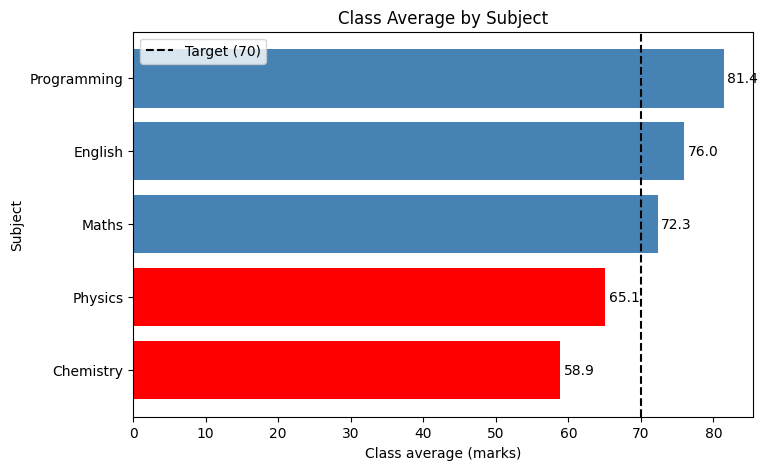


Q25: file exists: True
     below target: ['Chemistry', 'Physics']


In [1]:
#25
import os
import pandas as pd
import matplotlib.pyplot as plt
 
subjects = ['Maths', 'Physics', 'Programming', 'Chemistry', 'English']
class_avg = [72.3, 65.1, 81.4, 58.9, 76.0]
target = 70
 
df = pd.DataFrame({'subject': subjects, 'avg': class_avg}).sort_values('avg')
colors = ['red' if v < target else 'steelblue' for v in df['avg']]
 
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(df['subject'], df['avg'], color=colors)
ax.axvline(target, color='black', linestyle='--', label='Target (70)')
for i, v in enumerate(df['avg']):
    ax.text(v + 0.5, i, f"{v}", va='center')
ax.set_xlabel('Class average (marks)')
ax.set_ylabel('Subject')
ax.set_title('Class Average by Subject')
ax.legend()
 
os.makedirs('task_4/figures', exist_ok=True)
fig.savefig('task_4/figures/subject_performance.png', dpi=300, bbox_inches='tight')
plt.show()
print("\nQ25: file exists:", os.path.exists('task_4/figures/subject_performance.png'))
print("     below target:", df.loc[df['avg'] < target, 'subject'].tolist())

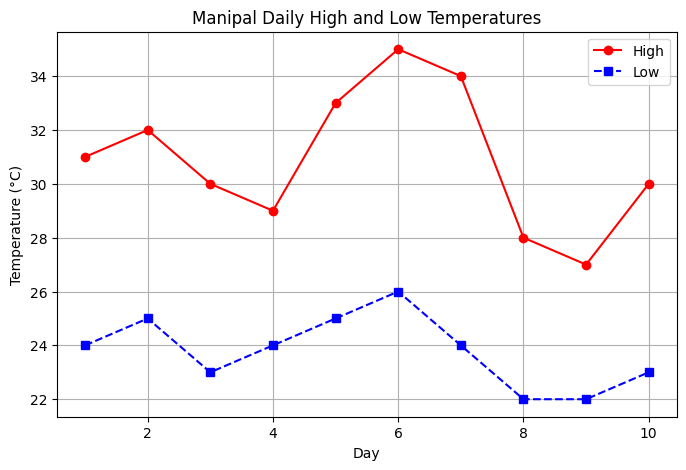

Q16: largest range = 10 °C on day 7
     highest temp = 35 °C on day 6


In [2]:
#16
import numpy as np
import matplotlib.pyplot as plt
 
days = np.arange(1, 11)
high = np.array([31, 32, 30, 29, 33, 35, 34, 28, 27, 30])
low = np.array([24, 25, 23, 24, 25, 26, 24, 22, 22, 23])
 
plt.figure(figsize=(8, 5))
plt.plot(days, high, marker='o', linestyle='-', color='red', label='High')
plt.plot(days, low, marker='s', linestyle='--', color='blue', label='Low')
plt.xlabel('Day')
plt.ylabel('Temperature (°C)')
plt.title('Manipal Daily High and Low Temperatures')
plt.grid(True)
plt.legend()
plt.show()
 
rng = high - low
print("Q16: largest range =", rng.max(), "°C on day", days[np.argmax(rng)])
print("     highest temp =", high.max(), "°C on day", days[np.argmax(high)])


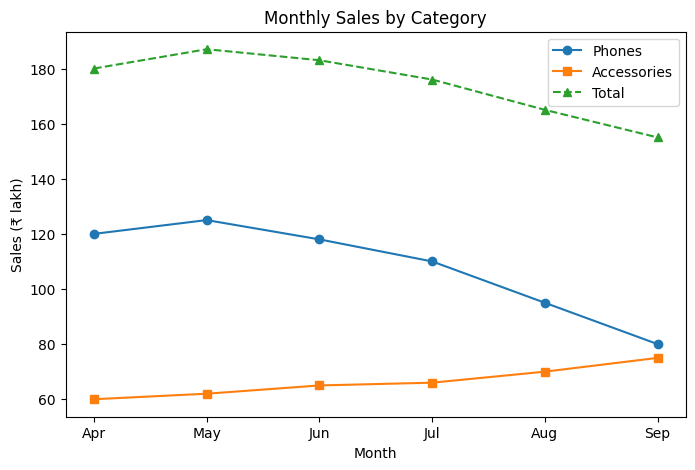


Q17: total peak month: May 187
     total change Apr->Sep: -25
     phones change: -40
     accessories change: 15


In [3]:
#17
import pandas as pd
import matplotlib.pyplot as plt
 
store = pd.DataFrame({'month': ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep'],
                      'phones': [120, 125, 118, 110, 95, 80],
                      'accessories': [60, 62, 65, 66, 70, 75]})
store['total'] = store['phones'] + store['accessories']
 
plt.figure(figsize=(8, 5))
plt.plot(store['month'], store['phones'], marker='o', label='Phones')
plt.plot(store['month'], store['accessories'], marker='s', label='Accessories')
plt.plot(store['month'], store['total'], marker='^', linestyle='--', label='Total')
plt.xlabel('Month')
plt.ylabel('Sales (₹ lakh)')
plt.title('Monthly Sales by Category')
plt.legend()
plt.show()
 
print("\nQ17: total peak month:", store.loc[store['total'].idxmax(), 'month'],
      store['total'].max())
print("     total change Apr->Sep:", store['total'].iloc[-1] - store['total'].iloc[0])
print("     phones change:", store['phones'].iloc[-1] - store['phones'].iloc[0])
print("     accessories change:", store['accessories'].iloc[-1] - store['accessories'].iloc[0])
 

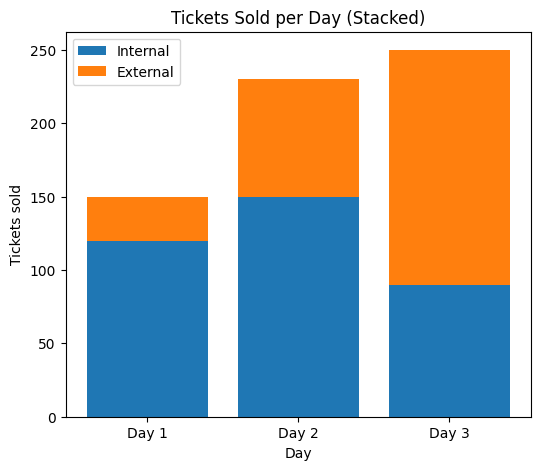

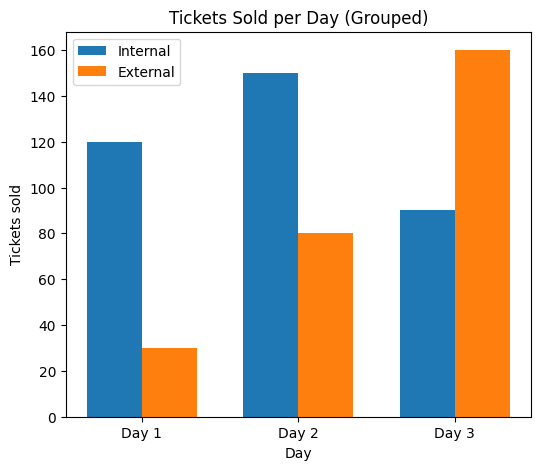


Q18:
      day  internal  external  total  external_share_%
0  Day 1       120        30    150              20.0
1  Day 2       150        80    230              34.8
2  Day 3        90       160    250              64.0


In [4]:
#18
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
 
day = ['Day 1', 'Day 2', 'Day 3']
internal = [120, 150, 90]
external = [30, 80, 160]
 
plt.figure(figsize=(6, 5))
plt.bar(day, internal, label='Internal')
plt.bar(day, external, bottom=internal, label='External')
plt.xlabel('Day')
plt.ylabel('Tickets sold')
plt.title('Tickets Sold per Day (Stacked)')
plt.legend()
plt.show()
 
x = np.arange(len(day))
w = 0.35
plt.figure(figsize=(6, 5))
plt.bar(x - w/2, internal, width=w, label='Internal')
plt.bar(x + w/2, external, width=w, label='External')
plt.xticks(x, day)
plt.xlabel('Day')
plt.ylabel('Tickets sold')
plt.title('Tickets Sold per Day (Grouped)')
plt.legend()
plt.show()
 
tickets = pd.DataFrame({'day': day, 'internal': internal, 'external': external})
tickets['total'] = tickets['internal'] + tickets['external']
tickets['external_share_%'] = (tickets['external'] / tickets['total'] * 100).round(1)
print("\nQ18:\n", tickets)
 

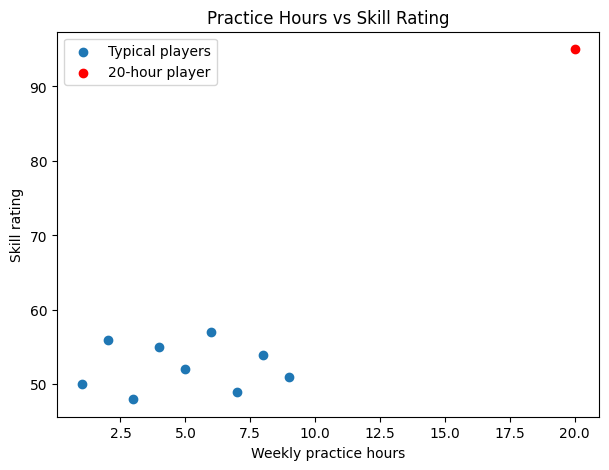


Q19: correlation (all) = 0.86
     correlation (without 20h) = 0.03


In [5]:
#Q19
import pandas as pd
import matplotlib.pyplot as plt
 
players = pd.DataFrame({'hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 20],
                        'rating': [50, 56, 48, 55, 52, 57, 49, 54, 51, 95]})
outlier = players['hours'] == 20
 
plt.figure(figsize=(7, 5))
plt.scatter(players.loc[~outlier, 'hours'], players.loc[~outlier, 'rating'], label='Typical players')
plt.scatter(players.loc[outlier, 'hours'], players.loc[outlier, 'rating'], color='red', label='20-hour player')
plt.xlabel('Weekly practice hours')
plt.ylabel('Skill rating')
plt.title('Practice Hours vs Skill Rating')
plt.legend()
plt.show()
 
print("\nQ19: correlation (all) =", round(players['hours'].corr(players['rating']), 2))
print("     correlation (without 20h) =",
      round(players.loc[~outlier, 'hours'].corr(players.loc[~outlier, 'rating']), 2))

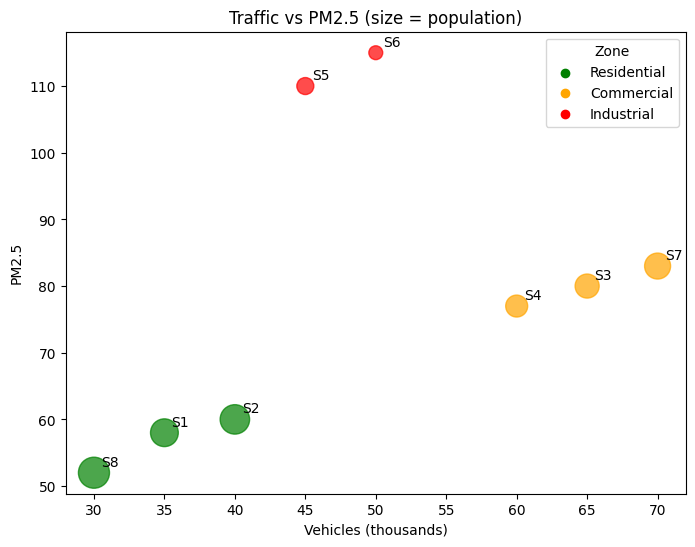

In [6]:
#Q20
import pandas as pd
import matplotlib.pyplot as plt
 
stations = pd.DataFrame({
    'station': ['S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8'],
    'vehicles_k': [35, 40, 65, 60, 45, 50, 70, 30],
    'pm25': [58, 60, 80, 77, 110, 115, 83, 52],
    'zone': ['Residential', 'Residential', 'Commercial', 'Commercial',
             'Industrial', 'Industrial', 'Commercial', 'Residential'],
    'population_k': [40, 45, 30, 25, 15, 10, 35, 50]})
 
color_map = {'Residential': 'green', 'Commercial': 'orange', 'Industrial': 'red'}
stations['color'] = stations['zone'].map(color_map)
 
plt.figure(figsize=(8, 6))
plt.scatter(stations['vehicles_k'], stations['pm25'],
            c=stations['color'], s=stations['population_k'] * 10, alpha=0.7)
for z, c in color_map.items():
    plt.scatter([], [], c=c, label=z)
for _, r in stations.iterrows():
    plt.text(r['vehicles_k'] + 0.5, r['pm25'] + 1, r['station'])
plt.xlabel('Vehicles (thousands)')
plt.ylabel('PM2.5')
plt.title('Traffic vs PM2.5 (size = population)')
plt.legend(title='Zone')
plt.show()
 